In [2]:
import pandas as pd
import matplotlib.pyplot as plt

monthly = pd.read_csv("results_monthly.csv")
causes = pd.read_csv("results_causes.csv")
routes = pd.read_csv("results_routes.csv")
airlines = pd.read_csv("results_airlines.csv")
time_of_day = pd.read_csv("results_time_of_day.csv")

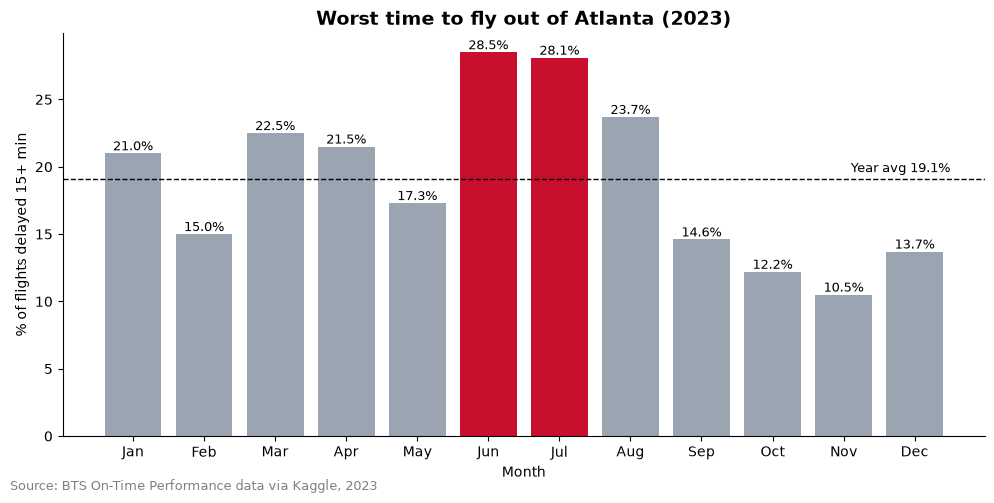

In [23]:
fig, ax = plt.subplots(figsize=(10, 5))

colors = ["#C8102E" if m in ["June", "July"] else "#9AA5B1" for m in monthly["Month_Name"]]

bars = ax.bar(monthly["Month_Name"].str[:3], monthly["pct_dep_delayed"], color=colors)

ax.axhline(19.1, color="black", linestyle="--", linewidth=1)
ax.text(11.5, 19.6, "Year avg 19.1%", ha="right", fontsize=9)

ax.bar_label(bars, fmt="%.1f%%", fontsize=9)
ax.set_title("Worst time to fly out of Atlanta (2023)", fontsize=14, weight="bold")
ax.set_ylabel("% of flights delayed 15+ min")
ax.set_xlabel("Month")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
fig.text(0.01, 0.01, "Source: BTS On-Time Performance data via Kaggle, 2023", fontsize=9, color="gray")
plt.savefig("chart1_monthly.png", dpi=150)
plt.show()

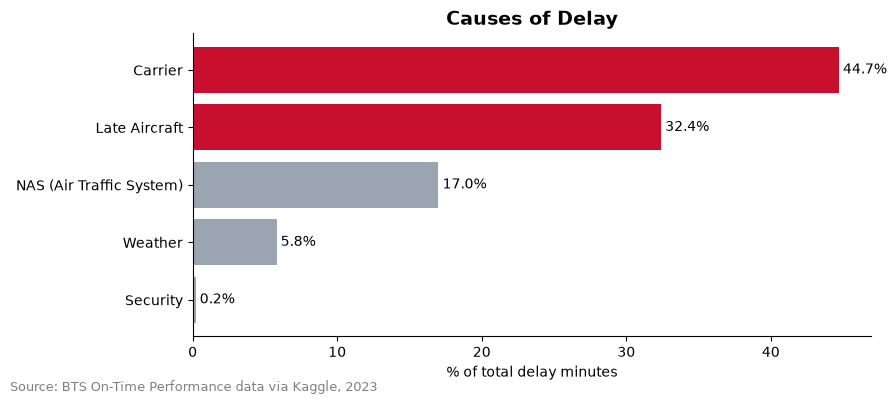

In [19]:
causes_sorted = causes.sort_values("pct_of_delay_minutes")

colors = ["#C8102E" if c in ["Carrier", "Late Aircraft"] else "#9AA5B1" for c in causes_sorted["cause"]]

fig, ax = plt.subplots(figsize=(9, 4))

bars = ax.barh(causes_sorted["cause"], causes_sorted["pct_of_delay_minutes"], color=colors)

ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=10)
ax.set_title("Causes of Delay", fontsize=14, weight="bold")
ax.set_xlabel("% of total delay minutes")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
fig.text(0.01, 0.01, "Source: BTS On-Time Performance data via Kaggle, 2023", fontsize=9, color="gray")
plt.savefig("chart2_causes.png", dpi=150)
plt.show()

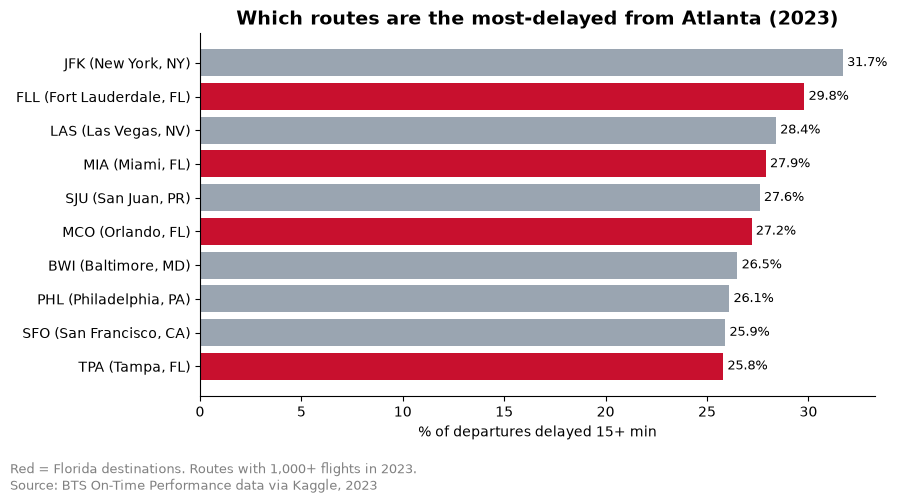

In [32]:
routes_sorted = routes.sort_values("pct_dep_delayed")

labels = routes_sorted["Arr_Airport"] + " (" + routes_sorted["Arr_CityName"] + ")"

colors = ["#C8102E" if city.endswith("FL") else "#9AA5B1" for city in routes_sorted["Arr_CityName"]]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.barh(labels, routes_sorted["pct_dep_delayed"], color=colors)

ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=9)
ax.set_title("Which routes are the most-delayed from Atlanta (2023)", fontsize=14, weight="bold")
ax.set_xlabel("% of departures delayed 15+ min")
fig.text(0.01, 0.01, "Red = Florida destinations. Routes with 1,000+ flights in 2023.\nSource: BTS On-Time Performance data via Kaggle, 2023",
fontsize=9, color="gray")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.savefig("chart3_routes.png", dpi=150)
plt.show()

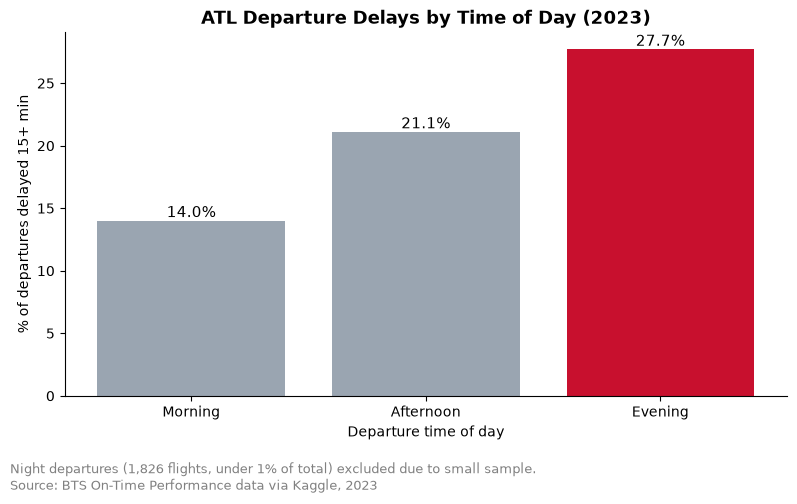

In [30]:
tod = time_of_day[time_of_day["DepTime_label"] != "Night"]

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(tod["DepTime_label"], tod["pct_dep_delayed"], color=["#9AA5B1", "#9AA5B1", "#C8102E"])

ax.bar_label(bars, fmt="%.1f%%", fontsize=11)
ax.set_title("ATL Departure Delays by Time of Day (2023)", fontsize=13, weight="bold")
ax.set_ylabel("% of departures delayed 15+ min")
ax.set_xlabel("Departure time of day")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout(rect=[0, 0.08, 1, 1])
fig.text(0.01, 0.01,"Night departures (1,826 flights, under 1% of total) excluded due to small sample.\nSource: BTS On-Time Performance data via Kaggle, 2023",
fontsize=9, color="gray")
plt.savefig("chart5_time_of_day.png", dpi=150)
plt.show()

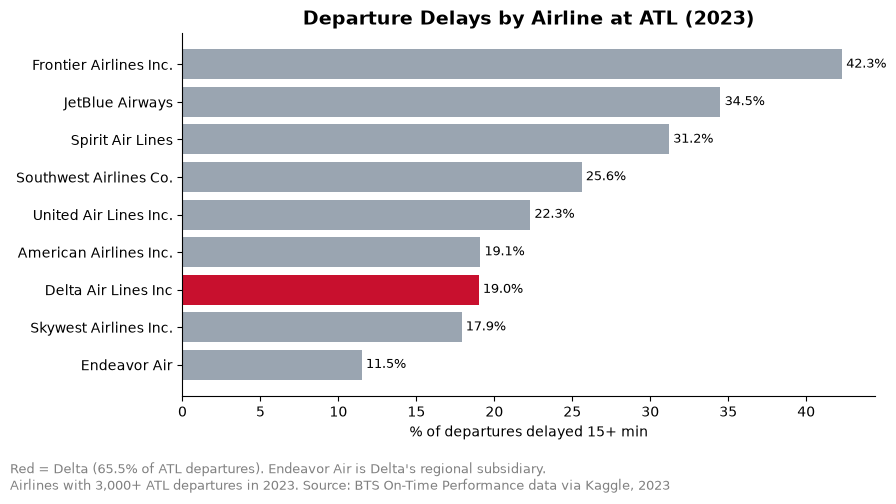

In [34]:
big_airlines = airlines[airlines["flights"] >= 3000].sort_values("pct_dep_delayed")

colors = ["#C8102E" if a == "Delta Air Lines Inc" else "#9AA5B1" for a in big_airlines["Airline"]]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.barh(big_airlines["Airline"], big_airlines["pct_dep_delayed"], color=colors)

ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=9)
ax.set_title("Departure Delays by Airline at ATL (2023)", fontsize=14, weight="bold")
ax.set_xlabel("% of departures delayed 15+ min")
ax.spines[["top", "right"]].set_visible(False)

fig.text(0.01, 0.01,
         "Red = Delta (65.5% of ATL departures). Endeavor Air is Delta's regional subsidiary.\nAirlines with 3,000+ ATL departures in 2023. Source: BTS On-Time Performance data via Kaggle, 2023",
         fontsize=9, color="gray")

plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.savefig("chart4_airlines.png", dpi=150)
plt.show()